## Data Cleaning and Quality Assessment
## Homework 4 - Anomaly Detection
## Hadi Seyed

### Question 1 - A Famous Experiment

#### Import librarie(s) and load the data

In [6]:
import pandas as pd

# url = "https://raw.githubusercontent.com/vincentarelbundock/Rdatasets/master/csv/datasets/morley.csv"
# morley = pd.read_csv(url)

pd.read_csv("morley.csv")

# Remove the extra row-index column
morley = morley.drop(columns=["rownames"], errors="ignore")

# Display the dataset
print("Dataset shape:", morley.shape)
display(morley.head())
print(morley.columns.tolist())

Dataset shape: (100, 3)


,Expt,Run,Speed
0,1,1,850
1,1,2,740
2,1,3,900
3,1,4,1070
4,1,5,930


['Expt', 'Run', 'Speed']


#### Anomaly detection code to prepare the data

In [7]:
# Check for missing values
print("Missing values:")
print(morley.isnull().sum())

# Make sure the columns have numeric values
for col in ["Expt", "Run", "Speed"]:
    morley[col] = pd.to_numeric(morley[col], errors="coerce")

# Remove rows with missing required values
morley = morley.dropna(subset=["Expt", "Run", "Speed"])

# Display a summary
display(morley.describe())

# Calculate the mean speed for each experiment
experiment_means = morley.groupby("Expt")["Speed"].mean()

print("Mean speed by experiment:")
display(experiment_means)

Missing values:
Expt     0
Run      0
Speed    0
dtype: int64


,Expt,Run,Speed
count,100.000000,100.000000,100.000000
mean,3.000000,10.500000,852.400000
std,1.421338,5.795331,79.010548
min,1.000000,1.000000,620.000000
25%,2.000000,5.750000,807.500000
50%,3.000000,10.500000,850.000000
75%,4.000000,15.250000,892.500000
max,5.000000,20.000000,1070.000000


Mean speed by experiment:


Expt
1    909.0
2    856.0
3    845.0
4    820.5
5    831.5
Name: Speed, dtype: float64

#### Define the IQR function

I used the interquartile range (IQR) method to detect outliers. The IQR is calculated as the difference between the third quartile (Q3) and the first quartile (Q1).

In [8]:
def calculate_iqr_bounds(series):
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    return lower_bound, upper_bound

#### Detect outliers within each experiment

In [9]:
morley["Within_Experiment_Outlier"] = False

experiment_bounds = []

for experiment, group in morley.groupby("Expt"):
    lower, upper = calculate_iqr_bounds(group["Speed"])

    outlier_index = group.index[
        (group["Speed"] < lower) |
        (group["Speed"] > upper)
    ]

    morley.loc[outlier_index, "Within_Experiment_Outlier"] = True

    experiment_bounds.append({
        "Experiment": experiment,
        "Q1": group["Speed"].quantile(0.25),
        "Q3": group["Speed"].quantile(0.75),
        "IQR": group["Speed"].quantile(0.75)
               - group["Speed"].quantile(0.25),
        "Lower_Bound": lower,
        "Upper_Bound": upper,
        "Outlier_Count": len(outlier_index)
    })

bounds_table = pd.DataFrame(experiment_bounds)

print("IQR boundaries and outlier counts by experiment:")
display(bounds_table.round(3))

print("Total within-experiment outliers:",
      int(morley["Within_Experiment_Outlier"].sum()))

print("Observations flagged within experiments:")
display(
    morley.loc[morley["Within_Experiment_Outlier"]]
    .sort_values(["Expt", "Speed"])
)

IQR boundaries and outlier counts by experiment:


,Experiment,Q1,Q3,IQR,Lower_Bound,Upper_Bound,Outlier_Count
0,1,850.0,980.0,130.0,655.00,1175.00,1
1,2,800.0,885.0,85.0,672.50,1012.50,0
2,3,840.0,880.0,40.0,780.00,940.00,5
3,4,767.5,865.0,97.5,621.25,1011.25,0
4,5,807.5,870.0,62.5,713.75,963.75,0


Total within-experiment outliers: 6
Observations flagged within experiments:


,Expt,Run,Speed,Within_Experiment_Outlier
13,1,14,650,True
46,3,7,620,True
44,3,5,720,True
45,3,6,720,True
49,3,10,950,True
48,3,9,970,True


#### Detect outliers across the entire dataset

In [10]:
global_lower, global_upper = calculate_iqr_bounds(morley["Speed"])

morley["Global_Outlier"] = (
    (morley["Speed"] < global_lower) |
    (morley["Speed"] > global_upper)
)

print("Global lower boundary:", round(global_lower, 3))
print("Global upper boundary:", round(global_upper, 3))

print("Number of global outliers:",
      int(morley["Global_Outlier"].sum()))

print("Global outlier observations:")
display(
    morley.loc[morley["Global_Outlier"]]
    .sort_values("Speed")
)

Global lower boundary: 680.0
Global upper boundary: 1020.0
Number of global outliers: 3
Global outlier observations:


,Expt,Run,Speed,Within_Experiment_Outlier,Global_Outlier
46,3,7,620,True,True
13,1,14,650,True,True
3,1,4,1070,False,True


#### Compare the two methods

In [11]:
comparison = pd.crosstab(
    morley["Within_Experiment_Outlier"],
    morley["Global_Outlier"],
    rownames=["Within experiment"],
    colnames=["Global"]
)

print("Comparison of outlier flags:")
display(comparison)

print("Flagged by both methods:",
      int((morley["Within_Experiment_Outlier"] &
           morley["Global_Outlier"]).sum()))

print("Flagged only within experiments:",
      int((morley["Within_Experiment_Outlier"] &
           ~morley["Global_Outlier"]).sum()))

print("Flagged only globally:",
      int((~morley["Within_Experiment_Outlier"] &
           morley["Global_Outlier"]).sum()))

Comparison of outlier flags:


Global,False,True
Within experiment,,
False,93,1
True,4,2


Flagged by both methods: 2
Flagged only within experiments: 4
Flagged only globally: 1


#### Compare means before and after removing outliers

In [12]:
means_before = (
    morley.groupby("Expt")["Speed"]
    .mean()
    .rename("Mean_Before")
)

cleaned = morley.loc[~morley["Within_Experiment_Outlier"]]

means_after = (
    cleaned.groupby("Expt")["Speed"]
    .mean()
    .rename("Mean_After")
)

mean_comparison = pd.concat(
    [means_before, means_after], axis=1
)

mean_comparison["Change_in_Mean"] = (
    mean_comparison["Mean_After"] -
    mean_comparison["Mean_Before"]
)

print("Experiment means before and after outlier removal:")
display(mean_comparison.round(3))

print("Range of experiment means before removal:",
      round(means_before.max() - means_before.min(), 3))

print("Range of experiment means after removal:",
      round(means_after.max() - means_after.min(), 3))

Experiment means before and after outlier removal:


,Mean_Before,Mean_After,Change_in_Mean
Expt,,,
1,909.0,922.632,13.632
2,856.0,856.000,0.000
3,845.0,861.333,16.333
4,820.5,820.500,0.000
5,831.5,831.500,0.000


Range of experiment means before removal: 88.5
Range of experiment means after removal: 102.132


#### Visualize measurements by experiment

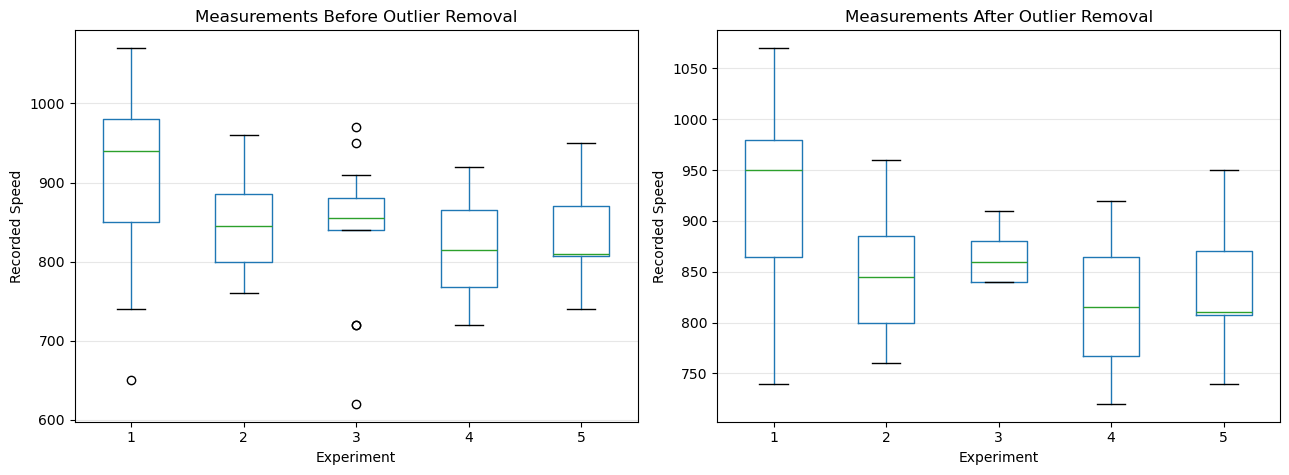

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

morley.boxplot(
    column="Speed",
    by="Expt",
    ax=axes[0],
    grid=False
)

axes[0].set_title("Measurements Before Outlier Removal")
axes[0].set_xlabel("Experiment")
axes[0].set_ylabel("Recorded Speed")
axes[0].grid(axis="y", alpha=0.3)

cleaned.boxplot(
    column="Speed",
    by="Expt",
    ax=axes[1],
    grid=False
)

axes[1].set_title("Measurements After Outlier Removal")
axes[1].set_xlabel("Experiment")
axes[1].set_ylabel("Recorded Speed")
axes[1].grid(axis="y", alpha=0.3)

plt.suptitle("")
plt.tight_layout()
plt.show()

#### Plot the mean comparison

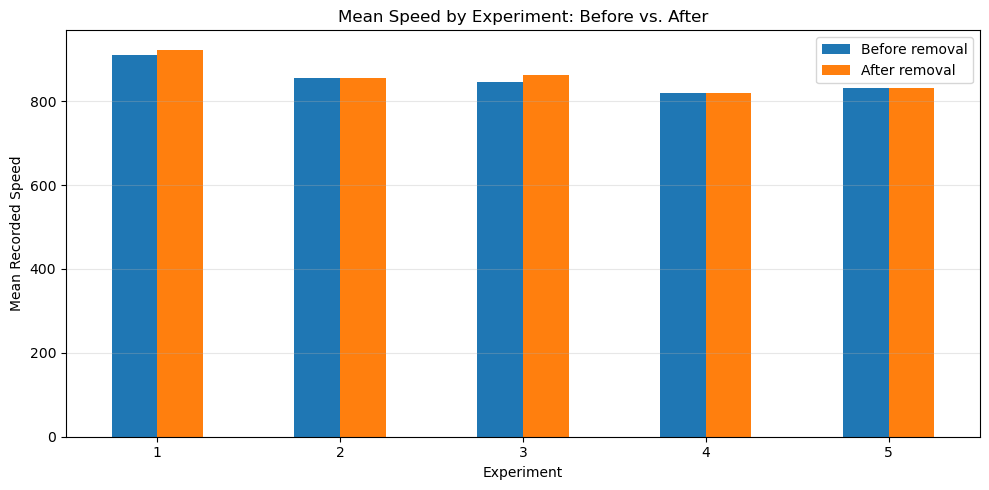

In [14]:
mean_comparison[["Mean_Before", "Mean_After"]].plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Mean Speed by Experiment: Before vs. After")
plt.xlabel("Experiment")
plt.ylabel("Mean Recorded Speed")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.legend(["Before removal", "After removal"])
plt.tight_layout()
plt.show()

### Question 2 - Misspelled Words

#### Load the names dataset

In [16]:
import pandas as pd
from pathlib import Path

# Load the downloaded dataset
file_path = Path("humans-names.csv")

if not file_path.exists():
    raise FileNotFoundError(
        "Please download humans-names.csv and place it "
        "in the same folder as your Jupyter Notebook."
    )

names = pd.read_csv(file_path)

print("Dataset shape:", names.shape)
print("Column names:", names.columns.tolist())
display(names.head())

Dataset shape: (25000, 3)
Column names: ['Name', 'Height', 'Weight']


,Name,Height,Weight
0,James,167.089607,64.806216
1,David,181.648633,78.281527
2,Barbara,176.272800,87.767722
3,John,173.270164,81.635672
4,Michael,172.181037,82.760794


#### Identify the name column

In [17]:
print(names.columns.tolist())

['Name', 'Height', 'Weight']


In [18]:
# Change this value if the dataset uses a different column name.
name_column = "Name"

if name_column not in names.columns:
    raise ValueError(
        f"'{name_column}' was not found. "
        f"Available columns: {names.columns.tolist()}"
    )

# Work on a separate copy of nonmissing name values.
name_series = (
    names[name_column]
    .dropna()
    .astype(str)
    .str.strip()
)

name_series = name_series[name_series != ""]

print("Number of nonmissing names:", len(name_series))
print("Number of unique spellings:", name_series.nunique())

Number of nonmissing names: 25000
Number of unique spellings: 249


#### Analyze name frequencies

In [19]:
name_counts = name_series.value_counts()

frequency_table = name_counts.rename_axis(
    "Name"
).reset_index(name="Frequency")

print("Most common spellings:")
display(frequency_table.head(20))

print("Least common spellings:")
display(frequency_table.tail(20))

Most common spellings:


,Name,Frequency
0,Elizabeth,1581
1,Barbara,1568
2,Jessica,1547
3,Jennifer,1534
4,Mary,1515
5,William,1492
6,Michael,1491
7,Patricia,1489
8,David,1485
9,Richard,1482


Least common spellings:


,Name,Frequency
229,Mariee,1
230,Mihael,1
231,Joen,1
232,Michal,1
233,Richadr,1
234,Josehp,1
235,lEizabeth,1
236,Jeninfer,1
237,Paetricia,1
238,Jame,1


#### Plot the most frequent names

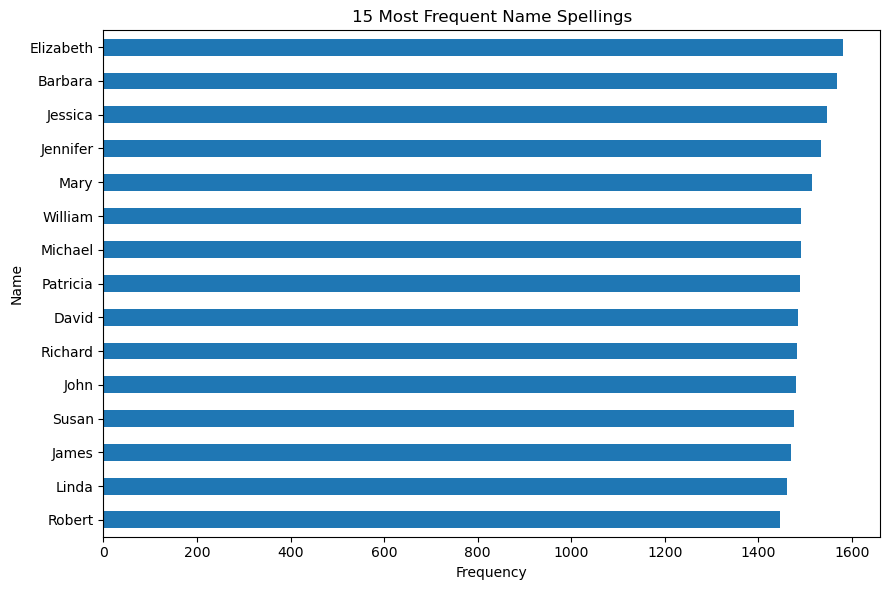

In [20]:
top_names = name_counts.head(15).sort_values()

top_names.plot(
    kind="barh",
    figsize=(9, 6)
)

plt.title("15 Most Frequent Name Spellings")
plt.xlabel("Frequency")
plt.ylabel("Name")
plt.tight_layout()
plt.show()

#### Find possible misspellings

I used difflib.SequenceMatcher *(String similarity)* to compare spellings. It produces a similarity ratio between 0 and 1, with higher values indicating greater similarity.

In [21]:
from difflib import SequenceMatcher

# Explicit heuristic thresholds
rare_frequency_threshold = 20
minimum_similarity = 0.80
maximum_length_difference = 2

# Names used as possible reference spellings
common_names = name_counts[
    name_counts >= rare_frequency_threshold
].index.tolist()

rare_names = name_counts[
    name_counts < rare_frequency_threshold
]

def similarity_ratio(name1, name2):
    return SequenceMatcher(
        None,
        str(name1).lower(),
        str(name2).lower()
    ).ratio()

def find_best_match(name, candidates):
    best_name = None
    best_score = 0.0

    for candidate in candidates:
        if name == candidate:
            continue

        score = similarity_ratio(name, candidate)

        if score > best_score:
            best_name = candidate
            best_score = score

    return best_name, best_score

candidate_results = []

for rare_name, frequency in rare_names.items():
    best_name, score = find_best_match(
        rare_name,
        common_names
    )

    length_difference = (
        abs(len(rare_name) - len(best_name))
        if best_name is not None
        else None
    )

    flagged = (
        best_name is not None
        and score >= minimum_similarity
        and length_difference <= maximum_length_difference
    )

    candidate_results.append({
        "Observed_Name": rare_name,
        "Frequency": int(frequency),
        "Suggested_Match": best_name,
        "Similarity": round(score, 3),
        "Length_Difference": length_difference,
        "Flag_For_Review": flagged
    })

candidate_table = pd.DataFrame(candidate_results)

candidate_table = candidate_table.sort_values(
    ["Flag_For_Review", "Similarity", "Frequency"],
    ascending=[False, False, True]
).reset_index(drop=True)

print("Number of rare spellings:", len(rare_names))
print("Number flagged for review:",
      int(candidate_table["Flag_For_Review"].sum()))

display(candidate_table.head(40))

Number of rare spellings: 231
Number flagged for review: 218


,Observed_Name,Frequency,Suggested_Match,Similarity,Length_Difference,Flag_For_Review
0,daviD,2,David,1.000,0,True
1,Elizaebeth,1,Elizabeth,0.947,1,True
2,Elizabeeth,1,Elizabeth,0.947,1,True
3,Elizeabeth,2,Elizabeth,0.947,1,True
4,Elizabeteh,2,Elizabeth,0.947,1,True
5,Eliezabeth,2,Elizabeth,0.947,1,True
6,Elizabeh,1,Elizabeth,0.941,1,True
7,eJennifer,1,Jennifer,0.941,1,True
8,Peatricia,1,Patricia,0.941,1,True
9,Patericia,1,Patricia,0.941,1,True


#### Examine the strongest candidates

In [22]:
likely_typos = candidate_table.loc[
    candidate_table["Flag_For_Review"]
].copy()

print("Potential misspellings for manual review:")
display(likely_typos.head(30))

Potential misspellings for manual review:


,Observed_Name,Frequency,Suggested_Match,Similarity,Length_Difference,Flag_For_Review
0,daviD,2,David,1.000,0,True
1,Elizaebeth,1,Elizabeth,0.947,1,True
2,Elizabeeth,1,Elizabeth,0.947,1,True
3,Elizeabeth,2,Elizabeth,0.947,1,True
4,Elizabeteh,2,Elizabeth,0.947,1,True
5,Eliezabeth,2,Elizabeth,0.947,1,True
6,Elizabeh,1,Elizabeth,0.941,1,True
7,eJennifer,1,Jennifer,0.941,1,True
8,Peatricia,1,Patricia,0.941,1,True
9,Patericia,1,Patricia,0.941,1,True


#### Inspect the full frequency of proposed matches

In [23]:
if not likely_typos.empty:
    likely_typos["Suggested_Match_Frequency"] = (
        likely_typos["Suggested_Match"]
        .map(name_counts)
    )

    likely_typos["Frequency_Ratio"] = (
        likely_typos["Suggested_Match_Frequency"] /
        likely_typos["Frequency"]
    )

    display(
        likely_typos.sort_values(
            ["Similarity", "Suggested_Match_Frequency"],
            ascending=[False, False]
        ).head(30)
    )
else:
    print(
        "No names met the current screening thresholds. "
        "Consider reviewing the thresholds or inspecting "
        "the rare spellings manually."
    )

,Observed_Name,Frequency,Suggested_Match,Similarity,Length_Difference,Flag_For_Review,Suggested_Match_Frequency,Frequency_Ratio
0,daviD,2,David,1.000,0,True,1485,742.500000
1,Elizaebeth,1,Elizabeth,0.947,1,True,1581,1581.000000
2,Elizabeeth,1,Elizabeth,0.947,1,True,1581,1581.000000
3,Elizeabeth,2,Elizabeth,0.947,1,True,1581,790.500000
4,Elizabeteh,2,Elizabeth,0.947,1,True,1581,790.500000
5,Eliezabeth,2,Elizabeth,0.947,1,True,1581,790.500000
6,Elizabeh,1,Elizabeth,0.941,1,True,1581,1581.000000
16,Elizabet,3,Elizabeth,0.941,1,True,1581,527.000000
7,eJennifer,1,Jennifer,0.941,1,True,1534,1534.000000
10,Jenneifer,1,Jennifer,0.941,1,True,1534,1534.000000


#### Create a proposed cleaned column

In [24]:
# Map only the spellings flagged for review.
# These are proposed changes, not verified corrections.
suggestion_map = dict(
    zip(
        likely_typos["Observed_Name"],
        likely_typos["Suggested_Match"]
    )
)

names["Name_Proposed"] = names[name_column].copy()

names["Name_Proposed"] = (
    names["Name_Proposed"]
    .astype("string")
    .str.strip()
    .map(lambda x: suggestion_map.get(x, x) if pd.notna(x) else x)
)

print("Original unique spellings:", name_series.nunique())
print(
    "Unique spellings after proposed changes:",
    names["Name_Proposed"].nunique()
)

display(
    names.loc[
        names[name_column].astype("string").str.strip()
        != names["Name_Proposed"],
        [name_column, "Name_Proposed"]
    ].drop_duplicates().head(30)
)

Original unique spellings: 249
Unique spellings after proposed changes: 31


,Name,Name_Proposed
292,eJohn,John
528,ohn,John
545,Jeon,Jon
559,Eliezabeth,Elizabeth
586,Jeoseph,Joseph
623,Roert,Robert
631,Lina,Linda
680,Jesseica,Jessica
701,Jospeh,Joseph
769,Jamse,James


#### Summarize the screening results

In [25]:
print("QUESTION 2 SUMMARY")
print("------------------")
print("Total name records:", len(name_series))
print("Unique spellings:", name_series.nunique())
print("Rare spellings:", len(rare_names))
print(
    "Potential typo candidates:",
    int(candidate_table["Flag_For_Review"].sum())
)

print("\nMost frequent names:")
display(frequency_table.head(10))

print("\nCandidate spellings:")
display(likely_typos.head(10))

QUESTION 2 SUMMARY
------------------
Total name records: 25000
Unique spellings: 249
Rare spellings: 231
Potential typo candidates: 218

Most frequent names:


,Name,Frequency
0,Elizabeth,1581
1,Barbara,1568
2,Jessica,1547
3,Jennifer,1534
4,Mary,1515
5,William,1492
6,Michael,1491
7,Patricia,1489
8,David,1485
9,Richard,1482



Candidate spellings:


,Observed_Name,Frequency,Suggested_Match,Similarity,Length_Difference,Flag_For_Review,Suggested_Match_Frequency,Frequency_Ratio
0,daviD,2,David,1.000,0,True,1485,742.5
1,Elizaebeth,1,Elizabeth,0.947,1,True,1581,1581.0
2,Elizabeeth,1,Elizabeth,0.947,1,True,1581,1581.0
3,Elizeabeth,2,Elizabeth,0.947,1,True,1581,790.5
4,Elizabeteh,2,Elizabeth,0.947,1,True,1581,790.5
5,Eliezabeth,2,Elizabeth,0.947,1,True,1581,790.5
6,Elizabeh,1,Elizabeth,0.941,1,True,1581,1581.0
7,eJennifer,1,Jennifer,0.941,1,True,1534,1534.0
8,Peatricia,1,Patricia,0.941,1,True,1489,1489.0
9,Patericia,1,Patricia,0.941,1,True,1489,1489.0
